# КР по модулю 1 — практическая часть



## Задание 1. (1 балл)

Используйте корпус `lenta.txt` из семинара 2 (ячейка ниже скачает его).

In [2]:
text = open('lenta.txt', encoding='utf-8').read()

In [3]:
import re
from collections import Counter

import regex
pattern = r'\b(?=\w*\p{Cyrillic})(?=\w*\p{Latin})\w+\b'

mixed_words = regex.findall(pattern, text)

word_counts = Counter(mixed_words)

if word_counts:
    most_common_word = word_counts.most_common(1)[0][0]
    print(f"Самое частотное слово: {most_common_word}")
    print(f"Оно встретилось {word_counts[most_common_word]} раз")

Самое частотное слово: Яndex
Оно встретилось 38 раз


Одним регулярным выражением найдите в **исходном тексте** корпуса (без какой-либо предобработки) примеры слов, в которых совмещается кириллица и латиница. Найдите самое частотное такое слово и вставьте его в форму как ответ.

### Задание 2 (1 балл)

Дана последовательность слов:

`об этом сообщает агентство интерфакс со ссылкой на пресс-службу`

Приведите весь текст корпуса `data/lenta.txt` к нижнему регистру и сделайте простую токенизацию: разбейте все по пробелам, удалите пунктуацию по краям токенов (`strip`) и отфильтруйте пустые строки, оставшиеся после этих шагов.

По частотам из корпуса рассчитайте для каждого триграмма в последовательности условную вероятность P(w3 | w1 w2) = count(w1 w2 w3) / count(w1 w2). Вставьте в форму триграмм с самой низкой вероятностью (три слова через пробел).

*если где-то получается деление но ноль, то пропустите это сочетание

In [8]:
import string
from collections import Counter

with open('lenta.txt', 'r', encoding='utf-8') as f:
    text = f.read().lower()

tokens = text.split()
tokens = [t.strip(string.punctuation) for t in tokens]
tokens = [t for t in tokens if t] # фильтруем пустые строки

bigram_counts = Counter()
trigram_counts = Counter()

for i in range(len(tokens) - 2):
    w1, w2, w3 = tokens[i], tokens[i+1], tokens[i+2]
    bigram_counts[(w1, w2)] += 1
    trigram_counts[(w1, w2, w3)] += 1

sequence = "об этом сообщает агентство интерфакс со ссылкой на пресс-службу".split()

results = []
for i in range(len(sequence) - 2):
    w1, w2, w3 = sequence[i], sequence[i+1], sequence[i+2]
    trigram = (w1, w2, w3)
    bigram = (w1, w2)
    
    count_trigram = trigram_counts[trigram]
    count_bigram = bigram_counts[bigram]
    
    if count_bigram == 0:
        continue
        
    prob = count_trigram / count_bigram
    results.append((prob, " ".join(trigram)))

results.sort(key=lambda x: x[0])

if results:
    print(f"Триграмм с самой низкой вероятностью: {''.join(results[0][1])}")
    print(f"Вероятность: {results[0][0]}")
    print("\nТоп-5 самых редких для проверки:")
    for prob, tri in results[:5]:
        print(f"{prob:.4f} : {tri}")

Триграмм с самой низкой вероятностью: сообщает агентство интерфакс
Вероятность: 0.020348837209302327

Топ-5 самых редких для проверки:
0.0203 : сообщает агентство интерфакс
0.0741 : агентство интерфакс со
0.0764 : этом сообщает агентство
0.1115 : ссылкой на пресс-службу
0.1599 : об этом сообщает


### Задание 3 (1 балл)

Загрузите датасет новостей `lenta_40k` из семинара 3 (ячейка ниже). Сделайте подвыборку из 500 текстов: `lenta.sample(500, random_state=8)`.

Посчитайте эмбеддинги этих текстов моделью `cointegrated/rubert-tiny2` (без префиксов). Рассчитайте косинусную близость всех со всеми (для каждой пары текстов) и найдите самую близкую пару текстов. 

Вставьте в форму первые слова обоих текстов через пробел (например, `Холдинг Американская`, порядок не важен).

!NB: Тексты должны быть разными

In [7]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

lenta = pd.read_csv("lenta_40k.csv.zip").sample(500, random_state=8)

model = SentenceTransformer('cointegrated/rubert-tiny2')

texts = lenta['text'].astype(str).tolist()

embeddings = model.encode(texts, normalize_embeddings=True, show_progress_bar=True)

sim_matrix = cosine_similarity(embeddings)

np.fill_diagonal(sim_matrix, -1)

idx_flat = np.argmax(sim_matrix)

i, j = np.unravel_index(idx_flat, sim_matrix.shape)

if i > j:
    i, j = j, i

first_word_1 = texts[i].split()[0] if texts[i].split() else ""
first_word_2 = texts[j].split()[0] if texts[j].split() else ""

print(f"Максимальная близость: {sim_matrix[i, j]:.4f}")
print(f"Текст 1: {texts[i][:100]}...")
print(f"Текст 2: {texts[j][:100]}...")
print(f"Ответ для формы: {first_word_1} {first_word_2}")

<class 'ModuleNotFoundError'>: No module named 'sentence_transformers'

В JupiterLite не подключается sentence_transformers, так что вот скриншот из колаба (((

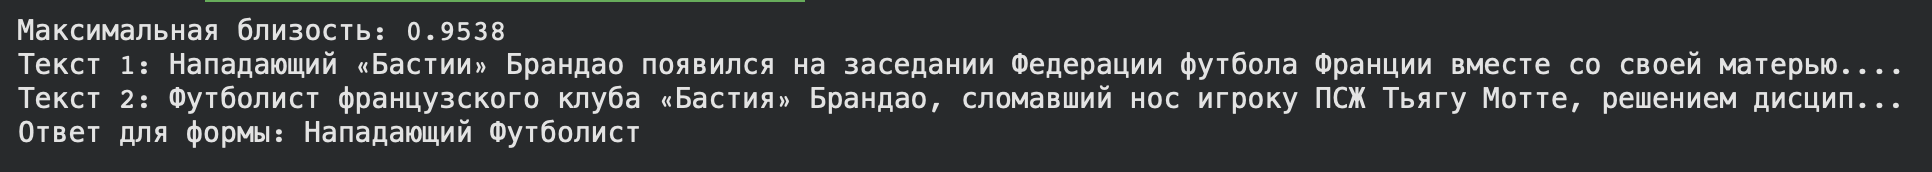